# Тема 3. Применение условных вероятностей в анализе данных
## Задание
На некотором наборе данных (выбрать самостоятельно, можно: https://www.kaggle.com/datasets) продемонстрировать применение условных вероятностей (см. пример с рейтингом автомобилей по типу кузова, Notebook с примером "Титаника"). Рассматриваемый набор данных необходимо описать (назначение, описание признаков).

**Импорт библиотек**

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

**Загрузка данных**

In [19]:
df = pd.read_csv('bedtime_screentime_sleep_debt.csv')
print("Размерность данных:", df.shape)

Размерность данных: (8500, 18)


In [7]:
# Быстрый взгляд на данные
df.head()

,user_id,age,gender,occupation_type,chronotype,bedtime_phone_minutes,primary_bedtime_app,screen_brightness_pct,blue_light_filter_active,caffeine_post_5pm_mg,physical_activity_min,sleep_latency_min,total_sleep_hours,deep_sleep_pct,rem_sleep_pct,morning_alarm_snoozes,next_day_fatigue_score,sleep_debt_category
0,USR-00001,29,Female,Healthcare / Shift Worker,Intermediate,179,Instagram / Reddit,54,1,0,21,84.4,3.20,23.5,22.2,7,10.0,Severe Sleep Debt
1,USR-00002,58,Female,Student,Intermediate,163,YouTube,76,1,92,72,86.7,4.06,18.0,21.5,7,10.0,Severe Sleep Debt
2,USR-00003,41,Female,Healthcare / Shift Worker,Night Owl,100,TikTok / Reels,59,0,45,23,70.5,3.20,18.1,20.5,7,10.0,Severe Sleep Debt
3,USR-00004,36,Non-Binary,Remote Tech,Intermediate,34,YouTube,52,0,97,49,38.1,6.99,21.6,22.4,1,1.7,Mild Deficit
4,USR-00005,23,Female,Healthcare / Shift Worker,Intermediate,27,TikTok / Reels,82,1,0,38,32.3,4.58,24.1,22.8,4,5.3,Moderate Debt


**Описание признаков набора данных**

In [8]:
print("\nСтолбцы:", df.columns.tolist())
df.info()


Столбцы: ['user_id', 'age', 'gender', 'occupation_type', 'chronotype', 'bedtime_phone_minutes', 'primary_bedtime_app', 'screen_brightness_pct', 'blue_light_filter_active', 'caffeine_post_5pm_mg', 'physical_activity_min', 'sleep_latency_min', 'total_sleep_hours', 'deep_sleep_pct', 'rem_sleep_pct', 'morning_alarm_snoozes', 'next_day_fatigue_score', 'sleep_debt_category']
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8500 entries, 0 to 8499
Data columns (total 18 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   user_id                   8500 non-null   object 
 1   age                       8500 non-null   int64  
 2   gender                    8500 non-null   object 
 3   occupation_type           8500 non-null   object 
 4   chronotype                8500 non-null   object 
 5   bedtime_phone_minutes     8500 non-null   int64  
 6   primary_bedtime_app       8500 non-null   object 
 7   screen_brightness_pc

In [20]:
# Создаем бинарную целевую переменную для анализа
df['severe_debt'] = (df['sleep_debt_category'] == 'Severe Sleep Debt').astype(int)

In [21]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8500 entries, 0 to 8499
Data columns (total 19 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   user_id                   8500 non-null   object 
 1   age                       8500 non-null   int64  
 2   gender                    8500 non-null   object 
 3   occupation_type           8500 non-null   object 
 4   chronotype                8500 non-null   object 
 5   bedtime_phone_minutes     8500 non-null   int64  
 6   primary_bedtime_app       8500 non-null   object 
 7   screen_brightness_pct     8500 non-null   int64  
 8   blue_light_filter_active  8500 non-null   int64  
 9   caffeine_post_5pm_mg      8500 non-null   int64  
 10  physical_activity_min     8500 non-null   int64  
 11  sleep_latency_min         8500 non-null   float64
 12  total_sleep_hours         8500 non-null   float64
 13  deep_sleep_pct            8500 non-null   float64
 14  rem_slee

In [9]:
# Пропущенные значения
print("Пропущенные значения:")
missing_data = df.isnull().sum()
missing_percent = (missing_data / len(df)) * 100
pd.DataFrame({'Количество пропусков': missing_data, 'Процент пропусков': missing_percent.round(2)})

Пропущенные значения:


,Количество пропусков,Процент пропусков
user_id,0,0.0
age,0,0.0
gender,0,0.0
occupation_type,0,0.0
chronotype,0,0.0
bedtime_phone_minutes,0,0.0
primary_bedtime_app,0,0.0
screen_brightness_pct,0,0.0
blue_light_filter_active,0,0.0
caffeine_post_5pm_mg,0,0.0


**Создадим сводную таблицу для первоначального взгляда**

In [10]:
print("Доля пользователей с сильным дефицитом сна по хронотипу и полу:")
pivot = pd.pivot_table(
    df, 
    values='severe_debt', 
    index=['chronotype'], 
    columns=['gender'], 
    aggfunc='mean',
    fill_value=0
)
pivot.round(4)

Доля пользователей с сильным дефицитом сна по хронотипу и полу:


gender,Female,Male,Non-Binary
chronotype,,,
Intermediate,0.0551,0.0632,0.0439
Morning Lark,0.0304,0.0214,0.0152
Night Owl,0.1503,0.1400,0.2500


## Вероятности и условные вероятности
### Простые вероятности
Вычислим априорные вероятности

In [11]:
# P(Severe Debt) - общая вероятность сильного дефицита сна
P_severe = df['severe_debt'].mean()
print(f"P(Severe Debt) = {P_severe:.3f}")

# Вероятности по хронотипам
for chrono in sorted(df['chronotype'].unique()):
    P_chrono = (df['chronotype'] == chrono).mean()
    print(f"P(Chronotype={chrono}) = {P_chrono:.3f}")

P(Severe Debt) = 0.076
P(Chronotype=Intermediate) = 0.456
P(Chronotype=Morning Lark) = 0.255
P(Chronotype=Night Owl) = 0.289


### Условная вероятность

**Задача.** Какова вероятность иметь сильный дефицит сна, если пользователь — "сова"?

Формула:

$$P_{Night Owl}(Severe Debt) = \frac{P(Severe Debt \cdot Night Owl)}{P(Night Owl)}$$

In [12]:
# Способ 1: Вручную по формуле
night_owls = df[df['chronotype'] == 'Night Owl']
P_NightOwl = (df['chronotype'] == 'Night Owl').mean()
P_Debt_and_NightOwl = ((df['severe_debt'] == 1) & (df['chronotype'] == 'Night Owl')).mean()
P_Debt_if_NightOwl = P_Debt_and_NightOwl / P_NightOwl
print(f"P(Severe Debt | Night Owl), вручную: {P_Debt_if_NightOwl:.3f}")

# Способ 2: Через фильтр
P_Debt_if_NightOwl_filter = night_owls['severe_debt'].mean()
print(f"P(Severe Debt | Night Owl), через фильтр: {P_Debt_if_NightOwl_filter:.3f}")

P(Severe Debt | Night Owl), вручную: 0.148
P(Severe Debt | Night Owl), через фильтр: 0.148


**Обобщение вычисления условных вероятностей**

Поскольку при вычислении условных вероятностей прослеживается общая схема их расчета, напишем функцию определения условных вероятностей, которая будет принимать:

* df — датафрейм;

* condition_col — название столбца с произошедшим событием;

* condition_val — значение произошедшего события;

* target_col — название столбца с целевым событием;

* target_val — значение целевого события.

In [23]:
def conditional_probability(df, condition_col, condition_val, target_col, target_val=1):
    subset = df[df[condition_col] == condition_val]
    if len(subset) == 0:
        return 0
    return (subset[target_col] == target_val).mean()

print("УСЛОВНЫЕ ВЕРОЯТНОСТИ СИЛЬНОГО ДЕФИЦИТА СНА:")
print("=" * 50)
print("\nПо полу:")
for gender in df['gender'].unique():
    prob = conditional_probability(df, 'gender', gender, 'severe_debt')
    print(f"  P(Severe Debt | Gender={gender}) = {prob:.3f}")

print("\nПо хронотипу:")
for chrono in sorted(df['chronotype'].unique()):
    prob = conditional_probability(df, 'chronotype', chrono, 'severe_debt')
    print(f"  P(Severe Debt | Chronotype={chrono}) = {prob:.3f}")

УСЛОВНЫЕ ВЕРОЯТНОСТИ СИЛЬНОГО ДЕФИЦИТА СНА:

По полу:
  P(Severe Debt | Gender=Female) = 0.076
  P(Severe Debt | Gender=Non-Binary) = 0.093
  P(Severe Debt | Gender=Male) = 0.075

По хронотипу:
  P(Severe Debt | Chronotype=Intermediate) = 0.059
  P(Severe Debt | Chronotype=Morning Lark) = 0.026
  P(Severe Debt | Chronotype=Night Owl) = 0.148


**Вывод:** условная вероятность позволяет уточнять и находить вероятности более сложных событий на основе вероятностей более сложных событий на основе вероятностей простых (связанных с ними) событий

### Формула полной вероятности
**Задача.** Найти общую вероятность сильного дефицита сна у людей $P(Severe Debt)$?

Формула полной вероятности:
$P(A) = \sum P_{B_i}(A) \cdot P(B_i)$

In [24]:
print("ФОРМУЛА ПОЛНОЙ ВЕРОЯТНОСТИ:")
print("P(Severe Debt) = Σ P(Severe Debt|Chronotype=i) * P(Chronotype=i)")
print("="*50)
total_prob = 0
prob_details = []

for chrono in sorted(df['chronotype'].unique()):
    P_chrono = (df['chronotype'] == chrono).mean()
    P_debt_given_chrono = conditional_probability(df, 'chronotype', chrono, 'severe_debt')
    
    # Вклад класса
    contribution = P_debt_given_chrono * P_chrono
    total_prob += contribution
    
    prob_details.append({
        'Chronotype': chrono,
        'P(Chrono)': P_chrono,
        'P(Debt|Chrono)': P_debt_given_chrono,
        'Вклад': contribution
    })

# Создание DataFrame
prob_df = pd.DataFrame(prob_details)

# Выводим таблицу с округлением и убираем лишние индексы для красоты
print(prob_df.round(3).to_string())

print(f"\nОбщая вероятность дефицита сна, рассчитанная по формуле полной вероятности: {total_prob:.3f}")
print(f"Общая вероятность дефицита сна, рассчитанная напрямую из данных: {df['severe_debt'].mean():.3f}")

ФОРМУЛА ПОЛНОЙ ВЕРОЯТНОСТИ:
P(Severe Debt) = Σ P(Severe Debt|Chronotype=i) * P(Chronotype=i)
     Chronotype  P(Chrono)  P(Debt|Chrono)  Вклад
0  Intermediate      0.456           0.059  0.027
1  Morning Lark      0.255           0.026  0.007
2     Night Owl      0.289           0.148  0.043

Общая вероятность дефицита сна, рассчитанная по формуле полной вероятности: 0.076
Общая вероятность дефицита сна, рассчитанная напрямую из данных: 0.076


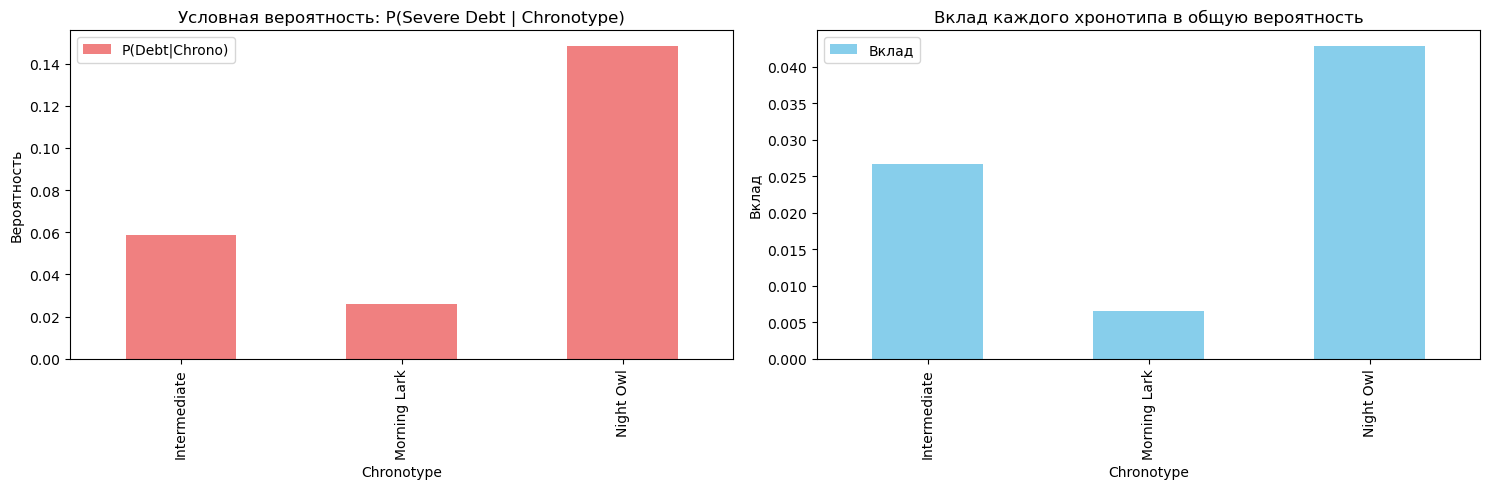

In [15]:
# Визуализируем вклад хронотипов
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))

prob_df.plot(x='Chronotype', y='P(Debt|Chrono)', kind='bar', ax=ax1, color='lightcoral')
ax1.set_title('Условная вероятность: P(Severe Debt | Chronotype)')
ax1.set_ylabel('Вероятность')

prob_df.plot(x='Chronotype', y='Вклад', kind='bar', ax=ax2, color='skyblue')
ax2.set_title('Вклад каждого хронотипа в общую вероятность')
ax2.set_ylabel('Вклад')

plt.tight_layout()
plt.show()

### Теорема Байеса
**Задача.** Какова вероятность того, что пользователь с сильным дефицитом сна - "сова"?

$P_{Severe Debt}(Night Owl) = \frac{P(Night Owl) \cdot P_{Night Owl}(Severe Debt)}{P(Severe Debt)}$

In [25]:
print("ТЕОРЕМА БАЙЕСА:")
P_S = df['severe_debt'].mean()
bayes_results = []

for chrono in sorted(df['chronotype'].unique()):
    P_A = (df['chronotype'] == chrono).mean()
    P_B_given_A = conditional_probability(df, 'chronotype', chrono, 'severe_debt')
    P_A_given_B = (P_B_given_A * P_A) / P_S
    
    bayes_results.append({
        'Chronotype': chrono,
        'P(Chrono)': P_A,
        'P(Debt|Chrono)': P_B_given_A,
        'P(Chrono|Debt)': P_A_given_B
    })

bayes_df = pd.DataFrame(bayes_results)
print(bayes_df.round(3))

ТЕОРЕМА БАЙЕСА:
     Chronotype  P(Chrono)  P(Debt|Chrono)  P(Chrono|Debt)
0  Intermediate      0.456           0.059           0.351
1  Morning Lark      0.255           0.026           0.087
2     Night Owl      0.289           0.148           0.563


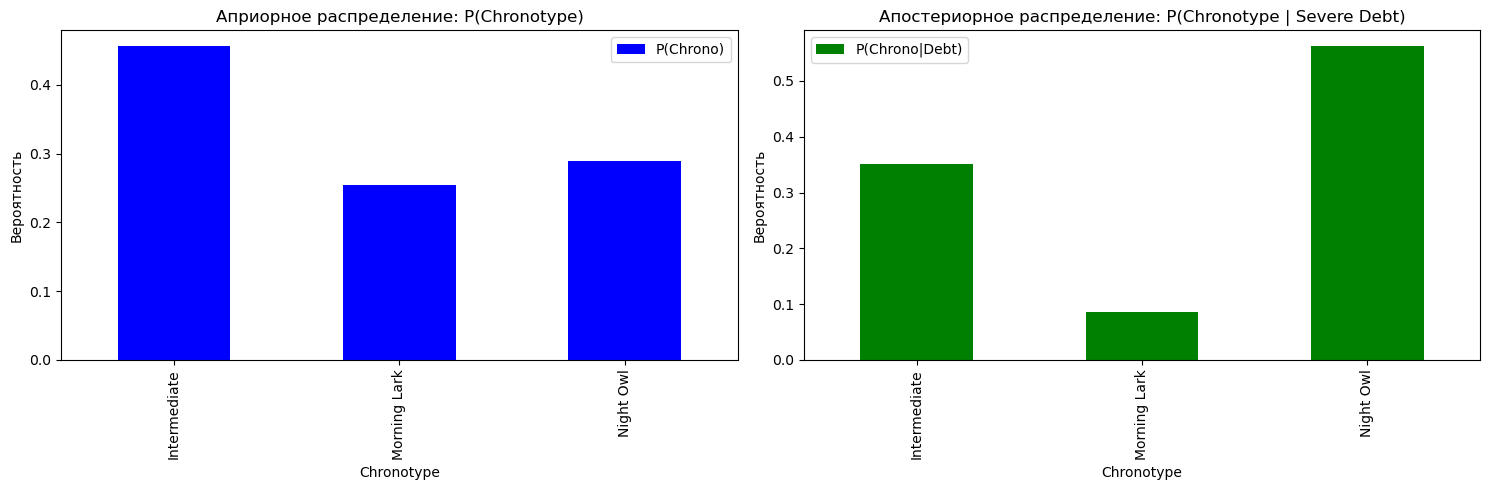

In [17]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))

bayes_df.plot(x='Chronotype', y='P(Chrono)', kind='bar', ax=ax1, color='blue')
ax1.set_title('Априорное распределение: P(Chronotype)')
ax1.set_ylabel('Вероятность')

bayes_df.plot(x='Chronotype', y='P(Chrono|Debt)', kind='bar', ax=ax2, color='green')
ax2.set_title('Апостериорное распределение: P(Chronotype | Severe Debt)')
ax2.set_ylabel('Вероятность')

plt.tight_layout()
plt.show()

**Вывод:** Теорема Байеса позволяет обновлять и корректировать вероятностные модели и решения по мере поступления новых данных.